In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from xgboost import XGBClassifier

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
df["pass"] = (df["G3"] >= 10).astype(int)
y = df["pass"]

X_all = df.drop(columns=["G3", "pass"])
X_no_grades = df.drop(columns=["G1", "G2", "G3", "pass"])

train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=y)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

def make_preprocessor(X):
    cat_cols = X.select_dtypes(include="object").columns.tolist()
    num_cols = X.select_dtypes(exclude="object").columns.tolist()
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

===== Set A (with G1, G2): held-out test set =====
              precision    recall  f1-score   support

        fail       0.76      0.96      0.85        26
        pass       0.98      0.85      0.91        53

    accuracy                           0.89        79
   macro avg       0.87      0.91      0.88        79
weighted avg       0.91      0.89      0.89        79

ROC-AUC: 0.941
Confusion matrix:
 [[25  1]
 [ 8 45]]


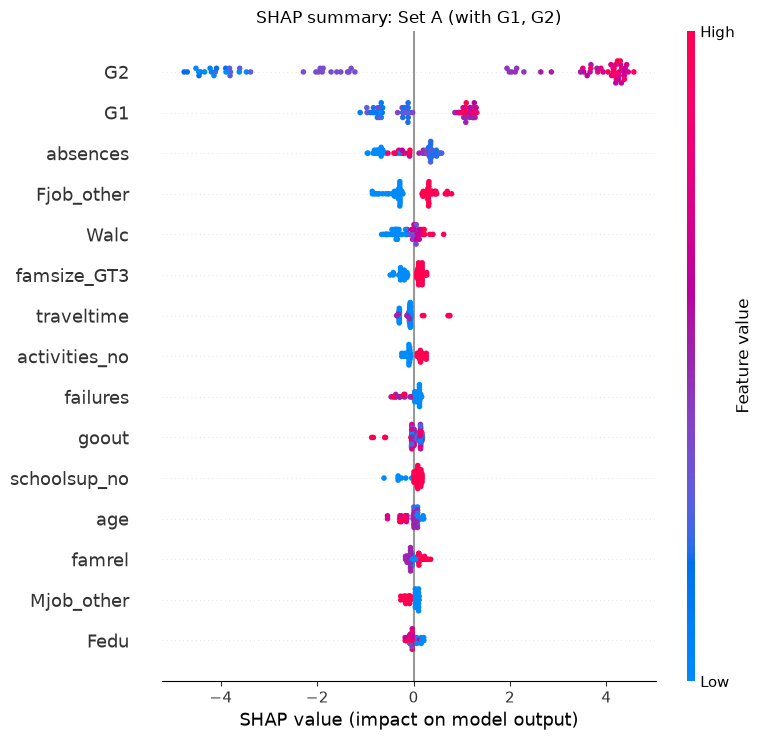

===== Set B (without G1, G2): held-out test set =====
              precision    recall  f1-score   support

        fail       0.47      0.31      0.37        26
        pass       0.71      0.83      0.77        53

    accuracy                           0.66        79
   macro avg       0.59      0.57      0.57        79
weighted avg       0.63      0.66      0.64        79

ROC-AUC: 0.591
Confusion matrix:
 [[ 8 18]
 [ 9 44]]


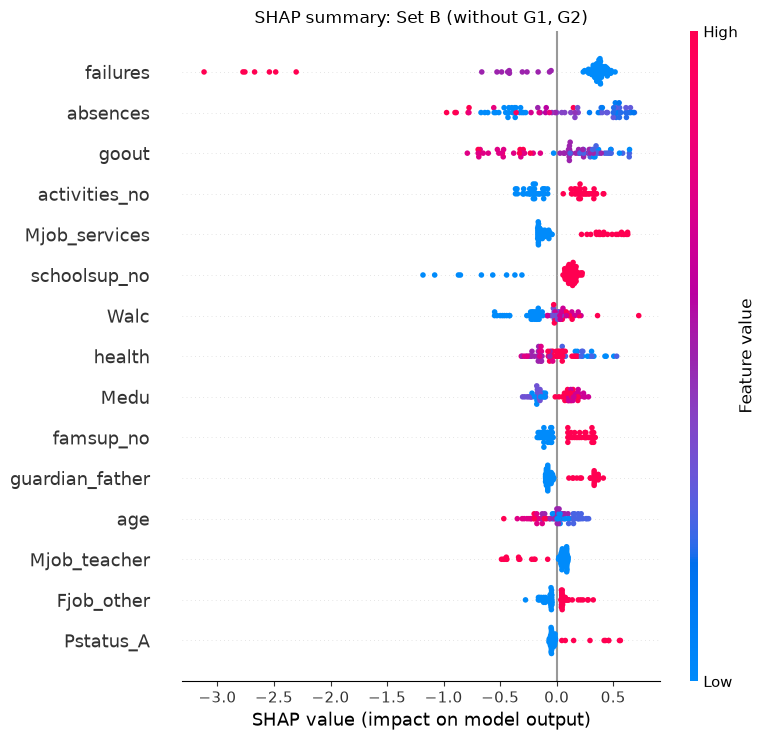

In [2]:
def final_analysis(X, label, fname):
    X_train, X_test = X.loc[train_idx], X.loc[test_idx]
    prep = make_preprocessor(X)
    Xtr = prep.fit_transform(X_train)
    Xte = prep.transform(X_test)
    if hasattr(Xtr, "toarray"):
        Xtr, Xte = Xtr.toarray(), Xte.toarray()
    names = prep.get_feature_names_out()
    names = [n.split("__", 1)[1] for n in names]

    clf = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                        eval_metric="logloss", random_state=42).fit(Xtr, y_train)
    pred = clf.predict(Xte)
    proba = clf.predict_proba(Xte)[:, 1]

    print(f"===== {label}: held-out test set =====")
    print(classification_report(y_test, pred, target_names=["fail", "pass"]))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))

    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(Xte)
    plt.figure()
    shap.summary_plot(sv, Xte, feature_names=names, max_display=15, show=False)
    plt.title(f"SHAP summary: {label}")
    plt.tight_layout()
    plt.savefig(f"../reports/{fname}", dpi=200, bbox_inches="tight")
    plt.show()

final_analysis(X_all, "Set A (with G1, G2)", "shap_set_A.png")
final_analysis(X_no_grades, "Set B (without G1, G2)", "shap_set_B.png")